# Чекпойнт 3. Первые ML-модели: прогноз доходности фьючерса SOLUSDT

**Цель этапа:** определить целевую переменную и горизонты прогноза, выбрать метрики, подготовить данные, обучить базовые модели с подбором гиперпараметров и честно сравнить их с простыми бейзлайнами.

**Что мы знаем из EDA (чекпойнт 2):** доходность стационарна, направление почти случайно (≈ 50% растущих дней), волатильность кластеризуется, связь с BTC сильная, но без опережения, параметры рынка меняются со временем. Отсюда план: прогнозировать доходность, сравнивать с бейзлайнами, проверять только по времени.

**Содержание**
1. Данные и признаки
2. Целевые переменные и горизонты
3. Схема проверки: walk-forward
4. Метрики
5. Регрессия: прогноз доходности
6. Классификация: вверх или вниз
7. Проверка устойчивости на другом периоде
8. Дополнительно: прогноз волатильности
9. Итоги и выводы

In [1]:
import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge, LogisticRegression
from sklearn.ensemble import (RandomForestRegressor, RandomForestClassifier,
                              HistGradientBoostingRegressor, HistGradientBoostingClassifier)
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import GridSearchCV

ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))
from features import build_dataset, feature_columns, HORIZONS
from modeling import (ZeroModel, MeanModel, PersistenceModel, walk_forward, time_series_cv,
                      regression_metrics, classification_metrics)

warnings.filterwarnings("ignore", category=UserWarning)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
plt.rcParams.update({"figure.figsize": (12, 4), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

SEED = 42
TEST_START = "2025-05-01"     # основной тест: последние ~1.5 года
ROBUST_START = "2022-06-01"   # проверка устойчивости: более длинный тест
REFIT_EVERY = 30              # переобучение раз в 30 дней

data = build_dataset(ROOT / "data" / "raw")
FEATURES = feature_columns(data)
print(f"Таблица: {len(data)} дней, {data.index.min():%Y-%m-%d} — {data.index.max():%Y-%m-%d}, признаков: {len(FEATURES)}")

Таблица: 2151 дней, 2020-12-13 — 2026-11-02, признаков: 31


## 1. Данные и признаки

Таблицу собирает функция `build_dataset` из `src/features.py`. Одна строка — один день t; **все признаки известны на закрытии дня t**, поэтому модель никогда не видит будущего. Первые ~90 дней уходят на «разогрев» скользящих окон.

| Группа | Признаки | Зачем (вывод EDA) |
|---|---|---|
| Прошлые доходности | `r_lag0`–`r_lag4` (SOL), `r_btc_lag0`–`r_btc_lag2` | слабая память в доходностях SOL (Льюнг–Бокс, PACF) |
| Импульс | `mom_7`, `mom_30`, `dist_ma50`, `btc_mom_7` | тренды и рыночные режимы |
| Волатильность | `vol_7`, `vol_30`, `vol_ratio`, `range`, `range_7`, `btc_vol_30` | кластеризация волатильности |
| Объём | `volume_z`, `taker_buy_share`, `taker_buy_share_7` | активность и агрессивные покупки |
| Связь с BTC | `corr_btc_30`, `corr_btc_90`, `beta_btc_90` | меняющаяся связь с BTC |
| Фьючерсы | `funding`, `funding_7`, `funding_change`, `funding_btc_7`, `basis`, `basis_7` | funding и базис — данные только фьючерсов |
| Календарь | `next_is_weekend` | эффект выходных |

In [2]:
groups = {
    "Прошлые доходности": [c for c in FEATURES if c.startswith("r_")],
    "Импульс": ["mom_7", "mom_30", "dist_ma50", "btc_mom_7"],
    "Волатильность": ["vol_7", "vol_30", "vol_ratio", "range", "range_7", "btc_vol_30"],
    "Объём": [c for c in FEATURES if c.startswith(("volume", "taker"))],
    "Связь с BTC": ["corr_btc_30", "corr_btc_90", "beta_btc_90"],
    "Фьючерсы": [c for c in FEATURES if c.startswith(("funding", "basis"))],
    "Календарь": ["next_is_weekend"],
}
assert sum(len(v) for v in groups.values()) == len(FEATURES)
print({k: len(v) for k, v in groups.items()})
print("Пропусков в признаках:", int(data[FEATURES].isna().sum().sum()))
data[FEATURES].describe().T[["mean", "std", "min", "max"]]

{'Прошлые доходности': 8, 'Импульс': 4, 'Волатильность': 6, 'Объём': 3, 'Связь с BTC': 3, 'Фьючерсы': 6, 'Календарь': 1}
Пропусков в признаках: 0


,mean,std,min,max
r_lag0,0.0019,0.0585,-0.7109,0.4092
r_lag1,0.0019,0.0585,-0.7109,0.4092
r_lag2,0.0019,0.0585,-0.7109,0.4092
r_lag3,0.0019,0.0585,-0.7109,0.4092
r_lag4,0.0019,0.0585,-0.7109,0.4092
r_btc_lag0,0.0007,0.0298,-0.1673,0.1787
r_btc_lag1,0.0007,0.0299,-0.1673,0.1787
r_btc_lag2,0.0007,0.0299,-0.1673,0.1787
mom_7,0.0133,0.1541,-0.9676,0.7356
mom_30,0.0556,0.3712,-1.0040,1.5981


**Проверка на утечку будущего.** Если какой-то признак случайно использует данные после дня t, его значение изменится, когда мы добавим в сырые данные более поздние дни. Обрезаем сырые файлы на нескольких датах, пересчитываем признаки и сравниваем с расчётом по полным данным: разница должна быть ровно нулевой.

In [3]:
import tempfile

RAW = ROOT / "data" / "raw"
for cut in ["2021-06-30", "2023-06-30", "2025-09-15"]:
    cut_ts = pd.Timestamp(cut, tz="UTC") + pd.Timedelta(days=1)
    with tempfile.TemporaryDirectory() as tmp:
        for p in RAW.glob("*.csv"):
            raw = pd.read_csv(p)
            ts = pd.to_datetime(raw["timestamp"], format="ISO8601", utc=True)
            raw[ts < cut_ts].to_csv(Path(tmp) / p.name, index=False)
        part = build_dataset(tmp)
    common = part.index.intersection(data.index)
    max_diff = (part.loc[common, FEATURES] - data.loc[common, FEATURES]).abs().max().max()
    print(f"обрезка на {cut}: общих дней {len(common)}, максимальная разница признаков {max_diff:.1e}")

обрезка на 2021-06-30: общих дней 200, максимальная разница признаков 0.0e+00
обрезка на 2023-06-30: общих дней 930, максимальная разница признаков 0.0e+00
обрезка на 2025-09-15: общих дней 1738, максимальная разница признаков 0.0e+00


**Вывод.** При трёх датах обрезки разница признаков ровно нулевая: ни один признак не использует данные после дня t. Таблица — 2151 день (13.12.2020 — 02.11.2026), 31 признак, пропусков нет.

## 2. Целевые переменные и горизонты

- **Регрессия:** будущая лог-доходность фьючерса SOL за h дней, $y_h(t) = \ln(P_{t+h} / P_t)$, для **h = 1, 3, 7 дней**. 1 день — краткосрочная торговля, 7 дней — недельная позиция; 3 дня — промежуточный горизонт.
- **Классификация:** направление, $up_h(t) = 1$, если $y_h(t) > 0$. Для стратегии на фьючерсах это сигнал «лонг или шорт».
- **Дополнительно (раздел 8):** реализованная волатильность SOL за следующие 7 дней — EDA показал, что волатильность предсказуема.

Почему доходность, а не цена: лог-цена нестационарна (ADF p = 0.13), а модель на цене формально точна, просто копируя вчерашнее значение (раздел 4 ноутбука EDA).

In [4]:
target_table = pd.DataFrame({
    f"h = {h}": {
        "наблюдений": int(data[f"y_{h}"].notna().sum()),
        "средняя доходность": data[f"y_{h}"].mean(),
        "ст. отклонение": data[f"y_{h}"].std(),
        "доля роста": data[f"up_{h}"].mean(),
    } for h in HORIZONS
})
target_table

,h = 1,h = 3,h = 7
наблюдений,"2,150.0000","2,148.0000","2,144.0000"
средняя доходность,0.0019,0.0057,0.0132
ст. отклонение,0.0585,0.0980,0.1542
доля роста,0.4991,0.5056,0.5000


## 3. Схема проверки: walk-forward

Перемешивать дни нельзя: тогда модель учится на будущем и проверяется на прошлом («подглядывает ответы»). Поэтому:

1. **Подбор гиперпараметров** — только на данных до `TEST_START` (1 мая 2025), кросс-валидация по времени `TimeSeriesSplit` (5 фолдов, каждый следующий фолд — позже предыдущего).
2. **Итоговая проверка** — на последних ~1.5 года (с 1 мая 2025), которые при подборе не использовались. Модель с подобранными параметрами идёт по тесту **walk-forward**: каждые 30 дней переобучается на всей истории, доступной к этому дню, и прогнозирует следующие 30 дней.
3. **Эмбарго h дней.** Таргет $y_h(s)$ становится известен только через h дней. Поэтому для прогноза на дату t модель обучается лишь на строках $s \le t - h$, а между фолдами кросс-валидации — зазор h дней.

Схема реализована в `src/modeling.py` (функции `walk_forward` и `time_series_cv`).

In [5]:
test_mask = data.index >= pd.Timestamp(TEST_START, tz="UTC")
split_table = pd.DataFrame({
    "подбор гиперпараметров (train)": [f"{data.index.min():%Y-%m-%d} — {data.index[~test_mask].max():%Y-%m-%d}", int((~test_mask).sum())],
    "итоговый тест (walk-forward)": [f"{data.index[test_mask].min():%Y-%m-%d} — {data.index[test_mask].max():%Y-%m-%d}", int(test_mask.sum())],
}, index=["период", "дней"]).T
split_table

,период,дней
подбор гиперпараметров (train),2020-12-13 — 2025-04-30,1600
итоговый тест (walk-forward),2025-05-01 — 2026-11-02,551


## 4. Метрики

**Регрессия:**
- **MAE** — средняя абсолютная ошибка (в долях: 0.026 = 2.6 п.п. доходности); устойчива к выбросам вроде краха FTX.
- **RMSE** — корень из средней квадратичной ошибки; сильнее штрафует крупные промахи.
- **R²oos** (вне выборки) $= 1 - \frac{\sum (y - \hat y)^2}{\sum y^2}$ — насколько модель лучше прогноза «доходность 0». R²oos > 0 — модель лучше, чем «ничего не предсказывать»; < 0 — хуже.
- **Точность направления** — доля дней, где знак прогноза совпал со знаком доходности, и **p-value** биномиального теста: можно ли отличить точность от 50% (монетки). Для h > 1 соседние таргеты перекрываются, поэтому тест считаем по каждому h-му дню.

**Классификация:** точность (порог вероятности 0.5), **ROC AUC** (0.5 — случайное угадывание, 1 — идеал) и тот же биномиальный тест.

**Бейзлайны**, которые модель обязана обойти:
- **«Ноль»** — доходность будет нулевой;
- **«Среднее»** — средняя доходность обучающей выборки;
- **«Завтра как сегодня»** — доходность за следующие h дней равна доходности за прошлые h дней;
- для классификации — **«всегда рост»**.

## 5. Регрессия: прогноз доходности

Три модели разной сложности:
- **Ridge** — линейная регрессия с регуляризацией (штраф за большие коэффициенты); признаки стандартизируются;
- **RandomForest** — случайный лес: среднее по сотням деревьев решений;
- **GradientBoosting** — градиентный бустинг (`HistGradientBoostingRegressor`): деревья строятся по очереди, каждое исправляет ошибки предыдущих; функция потерь — абсолютная ошибка.

Гиперпараметры подбираются перебором по сетке (`GridSearchCV`) по средней абсолютной ошибке на кросс-валидации.

In [6]:
REG_MODELS = {
    "Ridge": (make_pipeline(StandardScaler(), Ridge()),
              {"ridge__alpha": [1, 10, 100, 1000, 10000]}),
    "RandomForest": (RandomForestRegressor(n_estimators=300, random_state=SEED, n_jobs=-1),
                     {"max_depth": [3, 6], "min_samples_leaf": [20, 100], "max_features": ["sqrt", 0.5]}),
    "GradientBoosting": (HistGradientBoostingRegressor(loss="absolute_error", random_state=SEED),
                         {"learning_rate": [0.03, 0.1], "max_depth": [2, 3],
                          "max_iter": [100, 300], "min_samples_leaf": [50, 150]}),
}


def train_mask(target: pd.Series, h: int, start: str) -> pd.Series:
    # строки до начала теста, чей таргет известен к началу теста
    return target.notna() & (data.index <= pd.Timestamp(start, tz="UTC") - pd.Timedelta(days=h))


reg_rows, reg_params, reg_preds = [], [], {}
for h in HORIZONS:
    y = data[f"y_{h}"]
    tr = train_mask(y, h, TEST_START)
    baselines = {"Ноль": ZeroModel(), "Среднее": MeanModel(), "Завтра как сегодня": PersistenceModel(h)}
    for name, model in baselines.items():
        p = walk_forward(model, data[FEATURES], y, TEST_START, h, REFIT_EVERY)
        reg_rows.append({"h": h, "модель": name, **regression_metrics(y, p, h)})
    for name, (est, grid) in REG_MODELS.items():
        gs = GridSearchCV(est, grid, cv=time_series_cv(5, h), scoring="neg_mean_absolute_error", n_jobs=-1)
        gs.fit(data.loc[tr, FEATURES], y[tr])
        p = walk_forward(gs.best_estimator_, data[FEATURES], y, TEST_START, h, REFIT_EVERY)
        reg_preds[(h, name)] = p
        reg_rows.append({"h": h, "модель": name, **regression_metrics(y, p, h)})
        reg_params.append({"h": h, "модель": name, "лучшие параметры": gs.best_params_, "MAE на CV": -gs.best_score_})

reg_results = pd.DataFrame(reg_rows).set_index(["h", "модель"])
pd.DataFrame(reg_params).set_index(["h", "модель"])

лучшие параметры  MAE на CV
h модель                                                                        
1 Ridge                                       {'ridge__alpha': 10000}     0.0396
  RandomForest      {'max_depth': 3, 'max_features': 'sqrt', 'min_...     0.0391
  GradientBoosting  {'learning_rate': 0.03, 'max_depth': 3, 'max_i...     0.0394
3 Ridge                                       {'ridge__alpha': 10000}     0.0715
  RandomForest      {'max_depth': 3, 'max_features': 'sqrt', 'min_...     0.0716
  GradientBoosting  {'learning_rate': 0.03, 'max_depth': 2, 'max_i...     0.0707
7 Ridge                                       {'ridge__alpha': 10000}     0.1210
  RandomForest      {'max_depth': 3, 'max_features': 'sqrt', 'min_...     0.1232
  GradientBoosting  {'learning_rate': 0.03, 'max_depth': 2, 'max_i...     0.1221

In [7]:
reg_results

MAE   RMSE  ...  точность_направления  p_value_направление
h модель                            ...                                           
1 Ноль               0.0263 0.0355  ...                   NaN                  NaN
  Среднее            0.0264 0.0356  ...                0.4873               0.7388
  Завтра как сегодня 0.0367 0.0490  ...                0.5182               0.2085
  Ridge              0.0263 0.0355  ...                0.4855               0.7657
  RandomForest       0.0262 0.0355  ...                0.4964               0.5844
  GradientBoosting   0.0265 0.0357  ...                0.4800               0.8366
3 Ноль               0.0468 0.0614  ...                   NaN                  NaN
  Среднее            0.0473 0.0621  ...                0.4927               0.6162
  Завтра как сегодня 0.0691 0.0890  ...                0.4526               0.8816
  Ridge              0.0470 0.0615  ...                0.4799               0.6713
  RandomForest       0.0468 0.0613  ...                0.5201               0.3287
  GradientBoosting   0.0473 0.0620  ...                0.4964               0.3287
7 Ноль               0.0703 0.0926  ...                   NaN                  NaN
  Среднее            0.0725 0.0951  ...                0.4669               0.6328
  Завтра как сегодня 0.1023 0.1310  ...                0.4835               0.4550
  Ridge              0.0708 0.0933  ...                0.4596               0.7859
  RandomForest       0.0711 0.0937  ...                0.4963               0.6328
  GradientBoosting   0.0724 0.0963  ...                0.4798               0.7142

[18 rows x 5 columns]

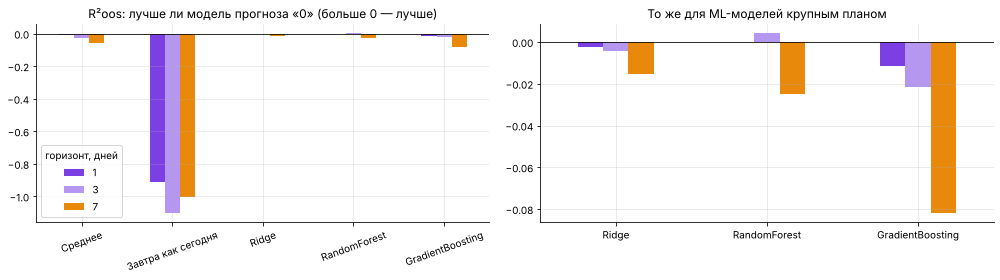

In [8]:
pivot = reg_results["R2_oos"].unstack("h")
order = ["Среднее", "Завтра как сегодня", "Ridge", "RandomForest", "GradientBoosting"]
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
pivot.loc[order].plot(kind="bar", ax=axes[0], color=["#7B3FE4", "#B596F0", "#E8890C"])
axes[0].axhline(0, color="k", lw=0.8)
axes[0].set_title("R²oos: лучше ли модель прогноза «0» (больше 0 — лучше)")
axes[0].set_xlabel(""); axes[0].tick_params(axis="x", rotation=20); axes[0].legend(title="горизонт, дней")
zoom = pivot.loc[["Ridge", "RandomForest", "GradientBoosting"]]
zoom.plot(kind="bar", ax=axes[1], color=["#7B3FE4", "#B596F0", "#E8890C"], legend=False)
axes[1].axhline(0, color="k", lw=0.8)
axes[1].set_title("То же для ML-моделей крупным планом")
axes[1].set_xlabel(""); axes[1].tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()

**Вывод.**
- **Ни одна модель заметно не обходит прогноз «доходность 0».** Лучший результат — у случайного леса: R²oos **+0.0002** (1 день) и **+0.0043** (3 дня), то есть ошибка меньше нулевого прогноза на доли процента. На 7 днях все модели хуже нуля (лучшая — Ridge, −0.0154).
- **Точность направления у ML-моделей — 46–52%,** и ни одно значение статистически не отличается от 50% (наименьшее p-value 0.33).
- **«Завтра как сегодня» сильно хуже нуля** (R²oos от −0.91 до −1.10): прошлое движение не продолжается на горизонте 1–7 дней.
- **Подбор гиперпараметров сам «говорит», что сигнала нет:** у Ridge на всех горизонтах выбрана максимальная регуляризация (alpha = 10 000), то есть модель почти игнорирует признаки и прогнозирует константу. Бустинг, наоборот, подстраивается под шум и ошибается сильнее всех среди ML-моделей.

Это совпадает с EDA: направление и величина доходности SOL почти случайны.

## 6. Классификация: вверх или вниз

Те же три семейства моделей, но предсказывают вероятность роста: **логистическая регрессия**, **случайный лес** и **градиентный бустинг**. Гиперпараметры подбираются по ROC AUC на кросс-валидации. Бейзлайн — «всегда рост».

In [9]:
CLF_MODELS = {
    "Logistic": (make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)),
                 {"logisticregression__C": [0.001, 0.01, 0.1, 1]}),
    "RandomForest": (RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1),
                     {"max_depth": [3, 6], "min_samples_leaf": [20, 100], "max_features": ["sqrt", 0.5]}),
    "GradientBoosting": (HistGradientBoostingClassifier(random_state=SEED),
                         {"learning_rate": [0.03, 0.1], "max_depth": [2, 3],
                          "max_iter": [100, 300], "min_samples_leaf": [50, 150]}),
}

clf_rows, clf_params = [], []
for h in HORIZONS:
    up = data[f"up_{h}"]
    tr = train_mask(up, h, TEST_START)
    p = walk_forward(DummyClassifier(strategy="constant", constant=1), data[FEATURES], up, TEST_START, h, REFIT_EVERY, proba=True)
    clf_rows.append({"h": h, "модель": "Всегда рост", **classification_metrics(up, p, h)})
    for name, (est, grid) in CLF_MODELS.items():
        gs = GridSearchCV(est, grid, cv=time_series_cv(5, h), scoring="roc_auc", n_jobs=-1)
        gs.fit(data.loc[tr, FEATURES], up[tr])
        cv_folds = [gs.cv_results_[f"split{i}_test_score"][gs.best_index_] for i in range(5)]
        p = walk_forward(gs.best_estimator_, data[FEATURES], up, TEST_START, h, REFIT_EVERY, proba=True)
        clf_rows.append({"h": h, "модель": name, **classification_metrics(up, p, h)})
        clf_params.append({"h": h, "модель": name, "лучшие параметры": gs.best_params_,
                           "AUC на CV (среднее)": gs.best_score_,
                           "AUC на CV по фолдам": np.round(cv_folds, 3).tolist()})

clf_results = pd.DataFrame(clf_rows).set_index(["h", "модель"])
pd.DataFrame(clf_params).set_index(["h", "модель"])

лучшие параметры  ...                  AUC на CV по фолдам
h модель                                                               ...                                     
1 Logistic                             {'logisticregression__C': 0.1}  ...   [0.55, 0.511, 0.526, 0.545, 0.494]
  RandomForest      {'max_depth': 3, 'max_features': 0.5, 'min_sam...  ...  [0.554, 0.549, 0.543, 0.525, 0.462]
  GradientBoosting  {'learning_rate': 0.03, 'max_depth': 2, 'max_i...  ...  [0.522, 0.485, 0.554, 0.542, 0.488]
3 Logistic                               {'logisticregression__C': 1}  ...  [0.387, 0.521, 0.499, 0.574, 0.535]
  RandomForest      {'max_depth': 6, 'max_features': 'sqrt', 'min_...  ...  [0.512, 0.545, 0.559, 0.506, 0.446]
  GradientBoosting  {'learning_rate': 0.03, 'max_depth': 3, 'max_i...  ...  [0.486, 0.543, 0.543, 0.538, 0.426]
7 Logistic                            {'logisticregression__C': 0.01}  ...     [0.39, 0.5, 0.547, 0.552, 0.435]
  RandomForest      {'max_depth': 6, 'max_features': 0.5, 'min_sam...  ...   [0.428, 0.617, 0.529, 0.549, 0.38]
  GradientBoosting  {'learning_rate': 0.03, 'max_depth': 3, 'max_i...  ...    [0.5, 0.524, 0.535, 0.498, 0.369]

[9 rows x 3 columns]

In [10]:
clf_results

точность  ROC_AUC  доля_прогнозов_роста  p_value_точность
h модель                                                                     
1 Всегда рост         0.4873   0.5000                1.0000            0.7388
  Logistic            0.4745   0.4447                0.1945            0.8919
  RandomForest        0.5109   0.4604                0.2200            0.3195
  GradientBoosting    0.5018   0.4706                0.3455            0.4830
3 Всегда рост         0.4927   0.5000                1.0000            0.6162
  Logistic            0.4781   0.4525                0.2701            0.5587
  RandomForest        0.4781   0.4520                0.3723            0.6162
  GradientBoosting    0.4635   0.4503                0.3613            0.3838
7 Всегда рост         0.4669   0.5000                1.0000            0.6328
  Logistic            0.5349   0.4865                0.2592            0.2141
  RandomForest        0.4265   0.4172                0.3860            0.8937
  GradientBoosting    0.4871   0.4678                0.3989            0.3672

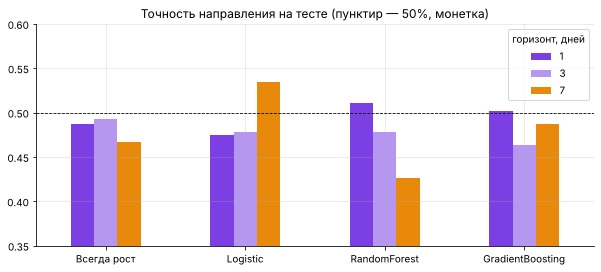

In [11]:
acc = clf_results["точность"].unstack("h")
ax = acc.loc[["Всегда рост", "Logistic", "RandomForest", "GradientBoosting"]].plot(
    kind="bar", color=["#7B3FE4", "#B596F0", "#E8890C"], figsize=(10, 4))
ax.axhline(0.5, color="k", lw=0.8, ls="--")
ax.set_ylim(0.35, 0.6)
ax.set_title("Точность направления на тесте (пунктир — 50%, монетка)")
ax.set_xlabel(""); ax.tick_params(axis="x", rotation=0); ax.legend(title="горизонт, дней")
plt.show()

**Вывод.**
- **Точность классификаторов на тесте — 43–53%.** Лучшая — логистическая регрессия на 7 днях (53.5%), но p = 0.21: от монетки не отличить.
- **ROC AUC на тесте 0.42–0.49 — ниже случайного угадывания (0.5).** При подборе на кросс-валидации AUC по фолдам скакал от 0.37 до 0.62: небольшой перевес в одних периодах сменялся провалом в других. Значит, закономерности, найденные на 2021–2024 годах, на 2025–2026 не переносятся — это смена рыночного режима, о которой предупреждал EDA.
- Модели чаще прогнозировали падение (рост — лишь в 19–40% дней), хотя на тесте росло около 47–49% дней: они перенесли «настроение» обучающего периода.

## 7. Проверка устойчивости на другом периоде

Может быть, модели просто не повезло с последними 1.5 годами? Повторяем всё для лучших по смыслу моделей на **более длинном тесте — с 1 июня 2022** (около 1600 дней, включая крах FTX, восстановление 2023–2024 и 2025–2026). Подбор гиперпараметров — только на данных до этой даты.

In [12]:
robust_rows = []
for h in HORIZONS:
    y, up = data[f"y_{h}"], data[f"up_{h}"]
    for name in ["Ridge", "RandomForest"]:
        est, grid = REG_MODELS[name]
        tr = train_mask(y, h, ROBUST_START)
        gs = GridSearchCV(est, grid, cv=time_series_cv(5, h), scoring="neg_mean_absolute_error", n_jobs=-1).fit(data.loc[tr, FEATURES], y[tr])
        p = walk_forward(gs.best_estimator_, data[FEATURES], y, ROBUST_START, h, REFIT_EVERY)
        m = regression_metrics(y, p, h)
        robust_rows.append({"h": h, "модель": name, "дней в тесте": len(p), "R2_oos": m["R2_oos"],
                            "точность": m["точность_направления"], "p_value": m["p_value_направление"], "ROC_AUC": np.nan})
    est, grid = CLF_MODELS["Logistic"]
    tr = train_mask(up, h, ROBUST_START)
    gs = GridSearchCV(est, grid, cv=time_series_cv(5, h), scoring="roc_auc", n_jobs=-1).fit(data.loc[tr, FEATURES], up[tr])
    p = walk_forward(gs.best_estimator_, data[FEATURES], up, ROBUST_START, h, REFIT_EVERY, proba=True)
    c = classification_metrics(up, p, h)
    robust_rows.append({"h": h, "модель": "Logistic", "дней в тесте": len(p), "R2_oos": np.nan,
                        "точность": c["точность"], "p_value": c["p_value_точность"], "ROC_AUC": c["ROC_AUC"]})

robust = pd.DataFrame(robust_rows).set_index(["h", "модель"])
robust

дней в тесте  R2_oos  точность  p_value  ROC_AUC
h модель                                                        
1 Ridge                 1615 -0.0296    0.4972   0.5983      NaN
  RandomForest          1615 -0.0117    0.4954   0.6547      NaN
  Logistic              1615     NaN    0.5015   0.4604   0.4867
3 Ridge                 1613 -0.0193    0.4923   0.7124      NaN
  RandomForest          1613 -0.0155    0.4830   0.7682      NaN
  Logistic              1613     NaN    0.4904   0.7936   0.4811
7 Ridge                 1609 -0.1480    0.4879   0.5784      NaN
  RandomForest          1609 -0.0534    0.4910   0.5263      NaN
  Logistic              1609     NaN    0.4823   0.8387   0.4807

**Вывод.** На длинном тесте с июня 2022 (около 1600 дней) картина та же: R²oos всех регрессий отрицательный (от −0.012 до −0.148), точность направления 48–50%, ROC AUC логистической регрессии 0.48–0.49. Неудача на последних 1.5 года — не случайность периода: с этими признаками направление доходности SOL на дневном горизонте не прогнозируется.

## 8. Дополнительно: прогноз волатильности

EDA показал, что сила движения (в отличие от направления) помнит прошлое. Проверяем, можно ли её прогнозировать.

- **Цель:** реализованная волатильность SOL за следующие 7 дней, $rv_7(t) = \sqrt{\frac{1}{7}\sum_{k=1}^{7} r_{t+k}^2}$.
- **Бейзлайны:** «как за прошлые 7 дней» (`vol_7`) и «как за прошлые 30 дней» (`vol_30`).
- **Модель:** Ridge. По совету EDA цель **нормируем на текущий уровень**: модель предсказывает $\ln(rv_7 / vol_{30})$ — во сколько раз волатильность будет выше или ниже обычной, — а затем прогноз переводится обратно. Так модель не ломается, когда рынок в целом становится спокойнее (волатильность SOL снизилась со 162% в 2021 до 62% в 2026).

In [13]:
rv = data["rv_7"]
rv_norm = np.log(data["rv_7"] / data["vol_30"])
tr = train_mask(rv_norm, 7, TEST_START)
gs_vol = GridSearchCV(make_pipeline(StandardScaler(), Ridge()), {"ridge__alpha": [1, 10, 100, 1000, 10000]},
                      cv=time_series_cv(5, 7), scoring="neg_mean_absolute_error").fit(data.loc[tr, FEATURES], rv_norm[tr])
p_norm = walk_forward(gs_vol.best_estimator_, data[FEATURES], rv_norm, TEST_START, 7, REFIT_EVERY)
idx = p_norm.index
vol_preds = {
    "как прошлые 7 дней": data.loc[idx, "vol_7"],
    "как прошлые 30 дней": data.loc[idx, "vol_30"],
    "Ridge (нормированная цель)": np.exp(p_norm) * data.loc[idx, "vol_30"],
}
rv_true = rv.loc[idx]
vol_table = pd.DataFrame({
    name: {"MAE": (rv_true - p).abs().mean(),
           "корреляция с фактом": np.corrcoef(rv_true, p)[0, 1],
           "средний прогноз": p.mean()}
    for name, p in vol_preds.items()
}).T
vol_table["MAE относительно «как прошлые 7 дней»"] = vol_table["MAE"] / vol_table.loc["как прошлые 7 дней", "MAE"] - 1
print(f"Средняя фактическая волатильность за 7 дней на тесте: {rv_true.mean():.4f}; alpha = {gs_vol.best_params_['ridge__alpha']}")
vol_table

Средняя фактическая волатильность за 7 дней на тесте: 0.0326; alpha = 1000


,MAE,корреляция с фактом,средний прогноз,MAE относительно «как прошлые 7 дней»
как прошлые 7 дней,0.0138,0.2289,0.0324,0.0000
как прошлые 30 дней,0.0114,0.2660,0.0347,-0.1690
Ridge (нормированная цель),0.0103,0.3499,0.0329,-0.2503


Самые влиятельные признаки (стандартизованные коэффициенты Ridge):


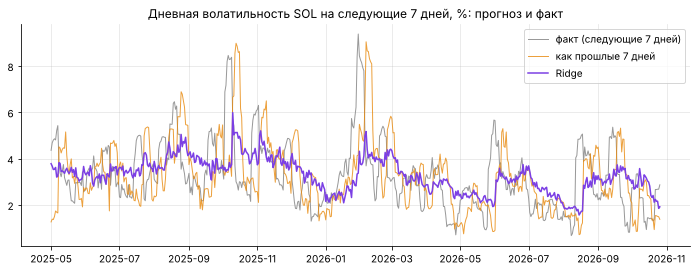

vol_30          -0.1036
btc_vol_30      -0.0624
volume_z         0.0580
vol_ratio        0.0369
funding_btc_7    0.0310
vol_7           -0.0301
corr_btc_30     -0.0283
range            0.0248
dtype: float64

In [14]:
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(rv_true * 100, color="#999999", lw=1, label="факт (следующие 7 дней)")
ax.plot(vol_preds["как прошлые 7 дней"] * 100, color="#E8890C", lw=1, alpha=0.8, label="как прошлые 7 дней")
ax.plot(vol_preds["Ridge (нормированная цель)"] * 100, color="#7B3FE4", lw=1.5, label="Ridge")
ax.set_title("Дневная волатильность SOL на следующие 7 дней, %: прогноз и факт")
ax.legend()
plt.show()

coefs = pd.Series(gs_vol.best_estimator_.named_steps["ridge"].coef_, index=FEATURES)
print("Самые влиятельные признаки (стандартизованные коэффициенты Ridge):")
coefs.reindex(coefs.abs().sort_values(ascending=False).index).head(8)

**Вывод.**
- **Волатильность прогнозируется.** Ridge с нормированной целью ошибается в среднем на **0.0103** (MAE), против 0.0138 у «как прошлые 7 дней» (**−25%**) и 0.0114 у более сильного бейзлайна «как прошлые 30 дней». Корреляция прогноза с фактом 0.35 (у бейзлайнов 0.23 и 0.27).
- **Нормировка сработала:** средний прогноз 0.0329 почти совпадает со средним фактом 0.0326, хотя рынок за время обучения стал заметно спокойнее.
- **Что влияет сильнее всего:** высокая волатильность за 30 дней (своя и BTC) — к снижению относительно этого уровня (всплески затухают); высокий объём и недавний всплеск (`vol_ratio`) — к росту.

**Зачем это стратегии:** даже без прогноза направления прогноз волатильности полезен — по нему можно выбирать размер позиции и плечо, ставить стоп-лоссы и заранее снижать риск перед бурными периодами (урок краха FTX).

## 9. Итоги и выводы

In [15]:
best_reg = reg_results.drop(["Ноль", "Среднее", "Завтра как сегодня"], level="модель")
summary = pd.DataFrame({
    f"h = {h}": {
        "лучшая ML-модель по R2oos": best_reg.loc[h]["R2_oos"].idxmax(),
        "её R2oos": best_reg.loc[h]["R2_oos"].max(),
        "лучшая точность направления (регрессия)": best_reg.loc[h]["точность_направления"].max(),
        "лучший ROC AUC (классификация)": clf_results.loc[h].drop("Всегда рост")["ROC_AUC"].max(),
        "доля роста на тесте": clf_results.loc[(h, "Всегда рост"), "точность"],
    } for h in HORIZONS
})
summary

,h = 1,h = 3,h = 7
лучшая ML-модель по R2oos,RandomForest,RandomForest,Ridge
её R2oos,0.0002,0.0043,-0.0154
лучшая точность направления (регрессия),0.4964,0.5201,0.4963
лучший ROC AUC (классификация),0.4706,0.4525,0.4865
доля роста на тесте,0.4873,0.4927,0.4669


In [16]:
OUT = ROOT / "data" / "processed"
OUT.mkdir(parents=True, exist_ok=True)
reg_results.to_csv(OUT / "cp3_regression_results.csv")
clf_results.to_csv(OUT / "cp3_classification_results.csv")
vol_table.to_csv(OUT / "cp3_volatility_results.csv")
print("Результаты сохранены в", OUT)

Результаты сохранены в /tmp/claude-0/-home-claude/6a5d157c-dba0-57d0-806a-27b965470d25/scratchpad/cp3/data/processed


### Основные выводы

1. **Целевая переменная и горизонты:** лог-доходность фьючерса SOL через 1, 3 и 7 дней (регрессия) и направление (классификация); дополнительно — волатильность на 7 дней.
2. **Данные:** 31 признак из 7 групп (доходности, импульс, волатильность, объём, связь с BTC, funding и базис, календарь), 2151 день; проверка подтвердила отсутствие утечки будущего.
3. **Проверка:** подбор гиперпараметров только на данных до 01.05.2025 с `TimeSeriesSplit` и зазором h дней; итоговая оценка — walk-forward на 551 дне с переобучением каждые 30 дней.
4. **Модели:** бейзлайны («ноль», «среднее», «завтра как сегодня», «всегда рост»), Ridge и логистическая регрессия, случайный лес, градиентный бустинг.
5. **Доходность и направление не прогнозируются.** Лучший R²oos — +0.004, точность направления 43–53% без статистической значимости, ROC AUC ниже 0.5; на длинном тесте с 2022 года — то же. Это согласуется с EDA и с тем, что ликвидный рынок быстро «съедает» простые закономерности.
6. **Волатильность прогнозируется:** ошибка на 25% меньше бейзлайна «как прошлые 7 дней» и меньше, чем у бейзлайна «как прошлые 30 дней».
7. **Отрицательный результат по доходности — тоже результат.** Он показывает, что честная проверка работает: модели, которые на кросс-валидации выглядели чуть лучше монетки, на новых данных этот перевес теряют.

### Что дальше

- **Чекпойнт 4 (сервис):** отдавать через FastAPI прогноз волатильности на 7 дней и вероятность роста с честной пометкой о её точности; признаки уже собраны функцией `build_dataset`, которую сервис может переиспользовать.
- **Чекпойнт 5 (улучшение моделей):** часовые данные (там опережение BTC и funding могут проявиться сильнее), признаки рыночного режима (бычий/медвежий рынок), open interest и ликвидации, другие цели — например, «будет ли движение больше 2σ» вместо знака доходности.
- **Стратегия (чекпойнт 7):** строить её вокруг прогноза волатильности — размер позиции и плечо от ожидаемого риска, — а сигнал направления проверять только против бейзлайна buy & hold с учётом комиссий и funding.